# Environmental Footprints of Housing
This code calculates environmental footprints of housing under a given set of energy use, energy technology, housing size of different building types, and transport use in relation to location and income.

For the analysis of current housing in NL the following datasets are needed:
- Set of assumptions: CBS microdata output
- Material use per building types
- Material use per solar PV capacity
- Material use per heat pump
- District heat source distribution
- Fuel use per pkm
- Infrastructural material use per pkm

In [526]:
# data processing modules
import pandas as pd
import numpy as np

# data visualisation modules
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
import seaborn as sns

# Display options
pd.options.display.float_format = '{:,.2f}'.format #limits printed decimal points to two
#pd.reset_option('^display.', silent=True) #option to reset the previous display option

In [527]:
def multiply_subcategories(df_detail, df_aggregate):
    """ 
    Multiplies a detailed dataframe with an aggregated dataframe

    Returns a detailed dataframe in which each each row is multiplied with the corresponding row in the aggregated dataframe
    Index level 0 of the detailed dataframe must match the index of the aggregated dataframe.
    
    Args:
        df_detail: multi-indexed dataframe of length a*b and width c
        df_aggregate: dataframe of length a and width c
    
    Returns: 
        pandas.DataFrame: Detailed dataframe of length a*b and width c in which each each row is multiplied with the corresponding row in the aggregated dataframe
        """
    df_new = pd.DataFrame(index=df_detail.index, columns=df_detail.columns)
    for i in df_aggregate.index:
        df_new.update(df_detail.xs(i, axis=0, level=0, drop_level=False).mul(df_aggregate.loc[i], axis=1))
        
    return df_new


In [528]:
def bubblechart(total, per, bubblesize, y_level, category_level, xlabel, ylabel, filename, bubblecolors=['#ffb000', '#fe6100','#dc267f','#785ef0', '#648fff','#808080']): #(use['size'+year+'_w1']*use['n_hhd']), use['n_hhdmem'+year], use['n_hhd'], 0, 1, 'm2 floor area per capita', 'household income level', 'm2_per_cap_inc_type'
    #floor area per income level
    use_m2_total_inc = total.groupby(level=y_level, sort=False).sum() #m2 total in each group summed by income level
    use_cap_total_inc = per.groupby(level=y_level, sort=False).sum() #no. of people in each group summed by income level
    use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group

    #floor area per income level and building type
    use_m2_total_inc_type = total.groupby(level=[y_level,category_level], sort=False).sum() #m2 total in each group summed by income level
    use_cap_total_inc_type = per.groupby(level=[y_level,category_level], sort=False).sum() #no. of people in each group summed by income level
    use_m2_per_cap_inc_type = use_m2_total_inc_type / use_cap_total_inc_type #m2/cap in each income group

    #preparing the dataframes for plotting
    df = use_m2_per_cap_inc
    df2=use_m2_per_cap_inc_type.rename('value').to_frame()
    df2['n_hhd'] = bubblesize.groupby(level=[y_level,category_level], sort=False).sum()
    df2 = df2.reset_index()

    #plot
    colors = ['#000000', #construction
                                '#fe6100', #buildings                                              
                                            '#648fff', #roads
                                            '#785ef0', #railways
                                            '#ffb000', #electricity
                                            '#808080', #other civil engineering
                                            '#000000', #construction
                                            ]
    fig = px.bar(df, x=df.values, y=df.index,  
                labels={'x':xlabel, 'inc_lab':ylabel, 'density_lab':ylabel}, 
                template='simple_white', 
                color_discrete_sequence=colors) 
    fig.update_layout(width=1000, height=500, 
                        #xaxis_tickformat = '.0%',
                        font=dict(size=18),
                        bargap=0.9,
                        legend=dict(
            orientation="h",
            #entrywidth=70,
            yanchor="bottom",
            y=1.02,
            xanchor="left",
            x=-0.25,
        ))

    df2=use_m2_per_cap_inc_type.rename('value').to_frame()
    df2['n_hhd'] = bubblesize.groupby(level=[y_level,category_level], sort=False).sum()
    
    count=0
    for i in df2.index.get_level_values(1).unique().to_list():
        df_plot = df2.xs(i, level=1)
        fig.add_trace(go.Scatter(
                y=df_plot.index, 
                x=df_plot['value'],
                mode='markers',
                name=i,
                legendrank=count,
                marker=dict(size=df_plot['n_hhd'],
                            sizemode='area',
                            sizeref=4*max(df2['n_hhd'])/(40.**2),
                            sizemin=4,
                            color=bubblecolors[count],
                            ),
                showlegend=True
            ))
        count=count+1

    fig.write_image('visualisations/bubblechart_'+filename+year+'.png', scale=3)
    fig.show()

## Foreground System: Calculate and Harmonize Direct Material, Fuel & Electricity Use

### Set of Assumptions
- configure assumptions
- import the CBS file

In [529]:
# Configurations
scenario = 'current'
year = '2019'
material_buildings_source = 'Oorschot-MPG' #alternative 'Oorschot' contains a different grouping (semi-detached and detached together, instead of row and semi-detached)
material_solarpv_source = 'ecoinvent'
material_heatpump_source = 'ecoinvent'
material_pkminfra_source = None
fuel_pkm_source = None
fuel_districtheating_source = None

# File import
if scenario == "current":
    use = pd.read_excel(
        "data_input/output/income typology construction density distance privacy "+year+".xlsx",
        #"data_input/output/income typology construction density distance privacy "+year+".xlsx",
        index_col=[0,1,2,3,4],
        header=[0],
    )

    mobility = pd.read_excel(
            "data_input/output/income density distance privacy odin "+year+".xlsx",
           #"data_input/output/income density distance privacy odin "+year+".xlsx",
            index_col=[0,1,2],
            header=[0],
        )

    # add transport use and vehicles per household to other variables, assumption: households with similar income, surrounding population density and distance to train station show similar mobility behaviour irrespective of building type or building age
    use_pkm = mobility['dist_carpp_py'] / mobility['n_hhd']#pkm per year per household
    use_pkm.name = 'car_pkm'
    use = use.join(use_pkm, on=['inc_lab','density_lab', 'distance_train_lab'])

    use_pkm = mobility['dist_transit_py'] / mobility['n_hhd'] #pkm per year per household
    use_pkm.name = 'transit_pkm'
    use = use.join(use_pkm, on=['inc_lab','density_lab', 'distance_train_lab'])

    use_pkm = mobility['dist_walk_py'] / mobility['n_hhd'] #pkm per year per household
    use_pkm.name = 'walk_pkm'
    use = use.join(use_pkm, on=['inc_lab','density_lab', 'distance_train_lab'])

    use_pkm = mobility['dist_cycle_py'] / mobility['n_hhd'] #pkm per year per household
    use_pkm.name = 'cycle_pkm'
    use = use.join(use_pkm, on=['inc_lab','density_lab', 'distance_train_lab'])

    use = use.join(mobility['car_hhd'], on=['inc_lab','density_lab', 'distance_train_lab']) #cars per household

    #weighting the pkm depending on number of adults in household i.e. more pkm allocated to households with more adults, less to households with fewer adults
    use_cap_per_hhd_mean = (use['n_adultmem'+year].groupby(level=[0,3,4], sort=False).sum()/use['n_hhd'].groupby(level=[0,3,4], sort=False).sum()) 
    use_cap_per_hhd_mean.name = 'n_mem_per_hhd_mobility'
    use = use.join(use_cap_per_hhd_mean, on=['inc_lab','density_lab', 'distance_train_lab'])
    use['mem_weight'] = (use['n_adultmem'+year]/use['n_hhd'])/use['n_mem_per_hhd_mobility']

    for i in ['car_pkm', 'transit_pkm', 'walk_pkm', 'cycle_pkm','car_hhd']:
        use[i] = use[i]*use['mem_weight']

    #change index labels to create more readable graphs
    use = use.rename(index={'detached (vrijstaand)':'detached', 'multiple fam (meergezins)':'multifamily', 'row house (tussenwoning)':'row house', 'semi-detached (2-1 kap) / corner (hoek)':'semi-detached'}, level=1)

    
    

In [530]:
use

inc_decile  \
inc_lab             typology_lab const_lab density_lab distance_train_lab               
decile 1 (poorest)  detached     pre 1945  very urban  nearest quintile             1   
                                                       2nd quintile                 1   
                                                       3nd quintile                 1   
                                                       4nd quintile                 1   
                                                       furthest quintile            1   
...                                                                               ...   
decile 10 (richest) multifamily  2006-2022 rural       nearest quintile            10   
                                                       2nd quintile                10   
                                                       3nd quintile                10   
                                                       4nd quintile                10   
                                                       furthest quintile           10   

                                                                           typology4_2019  \
inc_lab             typology_lab const_lab density_lab distance_train_lab                   
decile 1 (poorest)  detached     pre 1945  very urban  nearest quintile                 1   
                                                       2nd quintile                     1   
                                                       3nd quintile                     1   
                                                       4nd quintile                     1   
                                                       furthest quintile                1   
...                                                                                   ...   
decile 10 (richest) multifamily  2006-2022 rural       nearest quintile                 4   
                                                       2nd quintile                     4   
                                                       3nd quintile                     4   
                                                       4nd quintile                     4   
                                                       furthest quintile                4   

                                                                           const_cat2019  \
inc_lab             typology_lab const_lab density_lab distance_train_lab                  
decile 1 (poorest)  detached     pre 1945  very urban  nearest quintile                1   
                                                       2nd quintile                    1   
                                                       3nd quintile                    1   
                                                       4nd quintile                    1   
                                                       furthest quintile               1   
...                                                                                  ...   
decile 10 (richest) multifamily  2006-2022 rural       nearest quintile                6   
                                                       2nd quintile                    6   
                                                       3nd quintile                    6   
                                                       4nd quintile                    6   
                                                       furthest quintile               6   

                                                                           density2019  \
inc_lab             typology_lab const_lab density_lab distance_train_lab                
decile 1 (poorest)  detached     pre 1945  very urban  nearest quintile              1   
                                                       2nd quintile                  1   
                                                       3nd quintile                  1   
                                                       4nd q

In [531]:
use[use['n_heatpump'+year].notna()].index.get_level_values(1).value_counts()

multifamily      484
row house        360
detached         285
semi-detached    280
Name: typology_lab, dtype: int64

In [532]:
np.allclose(use['size'+year+'_w1']/use['mean_hhd'], use['size'+year+'_w1']*use['n_hhd']/use['n_hhdmem'+year], equal_nan=True)

True

In [533]:
(use['size'+year+'_w1']*use['n_hhd']) / (use['size'+year+'pp_w1']*use['n_hhdmem'+year]) #use the size per household to stay consistent with total floor space

inc_lab              typology_lab  const_lab  density_lab  distance_train_lab
decile 1 (poorest)   detached      pre 1945   very urban   nearest quintile     0.92
                                                           2nd quintile         0.91
                                                           3nd quintile         0.83
                                                           4nd quintile         1.33
                                                           furthest quintile     NaN
                                                                                ... 
decile 10 (richest)  multifamily   2006-2022  rural        nearest quintile     1.00
                                                           2nd quintile         0.78
                                                           3nd quintile         0.90
                                                           4nd quintile         0.86
                                                           furthest quin

In [534]:
use.index.levels[2]

Index(['1946-1964', '1965-1974', '1975-1991', '1992-2005', '2006-2022',
       'pre 1945'],
      dtype='object', name='const_lab')

<AxesSubplot: xlabel='inc_lab'>

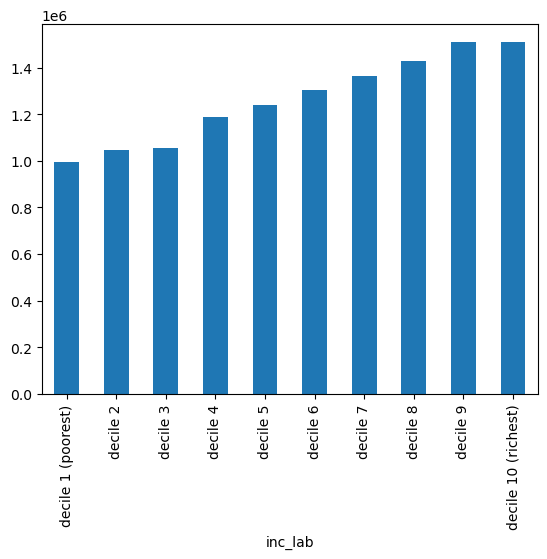

In [535]:
use['n_adultmem'+year].groupby(level=0, sort=False).sum().plot(kind='bar') 

In [536]:
use['n_heatpump'+year].sum()

57720.0

In [537]:
use['n_cityheating'+year].sum()

408105.0

In [538]:
(use['size'+year+'_w1']*use['n_hhd']).sum()

847527450.9843445

In [539]:
use['n_hhd']

inc_lab              typology_lab  const_lab  density_lab  distance_train_lab
decile 1 (poorest)   detached      pre 1945   very urban   nearest quintile     130.00
                                                           2nd quintile         130.00
                                                           3nd quintile          45.00
                                                           4nd quintile          25.00
                                                           furthest quintile       NaN
                                                                                 ...  
decile 10 (richest)  multifamily   2006-2022  rural        nearest quintile      20.00
                                                           2nd quintile          20.00
                                                           3nd quintile         130.00
                                                           4nd quintile         280.00
                                                    

In [540]:
use['n_hhdmem'+year]/use['n_hhd']

inc_lab              typology_lab  const_lab  density_lab  distance_train_lab
decile 1 (poorest)   detached      pre 1945   very urban   nearest quintile     2.00
                                                           2nd quintile         1.81
                                                           3nd quintile         2.22
                                                           4nd quintile         1.80
                                                           furthest quintile     NaN
                                                                                ... 
decile 10 (richest)  multifamily   2006-2022  rural        nearest quintile     2.00
                                                           2nd quintile         2.50
                                                           3nd quintile         2.04
                                                           4nd quintile         2.29
                                                           furthest quin

In [541]:
bubblechart(use['n_hhdmem'+year], use['n_hhd'], use['n_hhd'], 0, 1, 'members per household', 'equivalized income level','cap_per_hhd_inc_type')

In [542]:
    df = use['n_hhdmem'+year].groupby(level=[1,2], sort=False).sum().reset_index()
    fig = px.bar(df, y='n_hhdmem'+year, x='typology_lab',color='const_lab', 
                 #text=df['percentage'].apply(lambda x: '{0:.1%}'.format(x)), 
                 labels={'n_hhdmem'+year:'Number of residents',
                         'typology_lab':'',
                         'const_lab':''}, 
                 template='simple_white', 
             color_discrete_sequence=px.colors.qualitative.Prism) 
    #fig.update_traces(textposition='inside')
    fig.update_layout(width=650, height=650, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=14),
                      legend=dict(
        traceorder='reversed',
        #orientation="h",
        #entrywidth=70,
        #yanchor="bottom",
        #y=1.02,
        #xanchor="left",
        #x=-0.25
    ))
    fig.update_traces(marker_line_width=0)
    fig.write_image('visualisations/stackedbars_cap_per_type_age'+year+'.png', scale=3)
    fig.show()

In [543]:
    df = use['n_hhdmem'+year].groupby(level=[1,0], sort=False).sum().reset_index()
    fig = px.bar(df, y='n_hhdmem'+year, x='typology_lab',color='inc_lab', 
                 #text=df['percentage'].apply(lambda x: '{0:.1%}'.format(x)), 
                 labels={'n_hhdmem'+year:'Number of residents',
                         'typology_lab':'',
                         'inc_lab':'income'}, 
                 template='simple_white', 
             color_discrete_sequence=px.colors.qualitative.Prism) 
    #fig.update_traces(textposition='inside')
    fig.update_layout(width=650, height=650, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=14),
                      legend=dict(
        traceorder='reversed',
        #orientation="h",
        #entrywidth=70,
        #yanchor="bottom",
        #y=1.02,
        #xanchor="left",
        #x=-0.25
    ))
    fig.update_traces(marker_line_width=0)
    fig.write_image('visualisations/stackedbars_cap_per_type_age'+year+'.png', scale=3)
    fig.show()

In [544]:
    df = use['n_hhdmem'+year].groupby(level=[0,1], sort=False).sum().reset_index()
    fig = px.bar(df, x='n_hhdmem'+year, y='typology_lab',color='inc_lab', 
                 #text=df['percentage'].apply(lambda x: '{0:.1%}'.format(x)), 
                 labels={'n_hhdmem'+year:'Number of residents',
                         'typology_lab':'',
                         'const_lab':''}, 
                 template='simple_white', 
             color_discrete_sequence=px.colors.qualitative.Prism) 
    #fig.update_traces(textposition='inside')
    fig.update_layout(width=1000, height=300, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=14),
                      legend=dict(
        orientation="h",
        #entrywidth=70,
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25
    ))
    fig.update_traces(marker_line_width=0)
    fig.write_image('visualisations/stackedbars_cap_per_type_age'+year+'.png', scale=3)
    fig.show()

### Service inequality visualisations: floor area, electricity, pkm

#### Floor area

In [545]:
bubblechart((use['size'+year+'_w1']*use['n_hhd']), use['n_hhdmem'+year], use['n_hhd'], 0, 1, 'm2 floor area per capita', 'equivalized income level', 'm2_per_cap_inc_type')

In [546]:
((use['size'+year+'_w1']*use['n_hhd'])/use['n_hhdmem'+year]).sort_values().head(30)

inc_lab             typology_lab   const_lab  density_lab  distance_train_lab
decile 2            row house      2006-2022  very urban   4nd quintile         32.39
decile 3            row house      2006-2022  very urban   4nd quintile         32.61
decile 1 (poorest)  multifamily    1946-1964  very urban   3nd quintile         32.76
decile 4            row house      2006-2022  very urban   furthest quintile    32.80
decile 5            row house      2006-2022  very urban   4nd quintile         32.84
decile 6            semi-detached  2006-2022  very urban   4nd quintile         33.06
decile 4            row house      2006-2022  very urban   4nd quintile         33.23
decile 1 (poorest)  row house      2006-2022  very urban   4nd quintile         33.36
decile 9            row house      1946-1964  very urban   furthest quintile    33.51
decile 8            semi-detached  2006-2022  very urban   furthest quintile    34.14
decile 5            row house      2006-2022  very urban   fur

In [547]:
((use['size'+year+'_w1']*use['n_hhd'])/use['n_hhdmem'+year]).sort_values(ascending=False).head(30)

inc_lab             typology_lab  const_lab  density_lab    distance_train_lab
decile 1 (poorest)  detached      pre 1945   very urban     4nd quintile         172.20
                                  1965-1974  very urban     2nd quintile         161.23
                    multifamily   1946-1964  rural          2nd quintile         155.45
                    detached      pre 1945   rural          2nd quintile         154.33
decile 4            detached      1975-1991  very urban     3nd quintile         148.03
decile 1 (poorest)  detached      pre 1945   rural          3nd quintile         145.31
                                                            4nd quintile         139.78
decile 8            detached      1965-1974  very urban     nearest quintile     134.59
decile 1 (poorest)  detached      1946-1964  high suburban  3nd quintile         133.65
                                  1975-1991  urban          3nd quintile         131.45
                                  pre 194

In [548]:
bubblechart((use['size'+year+'_w1']*use['n_hhd']), use['n_hhd'], use['n_hhd'], 0, 1, 'm2 floor area per household', 'equivalized income level', 'm2_per_hhd_inc_type')

'interpretation: household size (especially adult members) increases with income level (exception when including children: lowest two levels because of single-parents), \nbut without strong correlation with the floor area per capita'

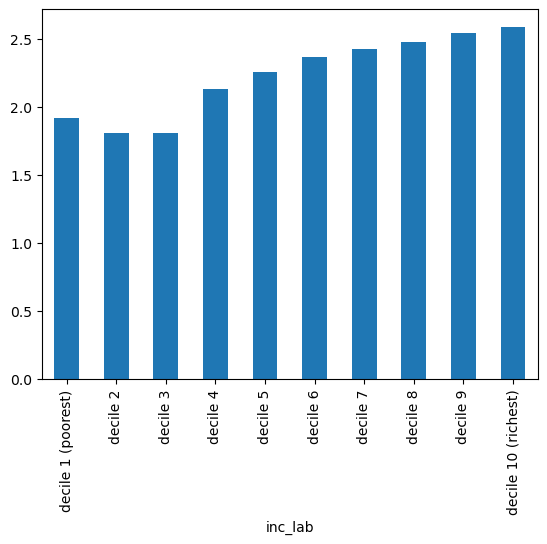

In [549]:
use_cap_total_inc = use['n_hhdmem'+year].groupby(level=0, sort=False).sum() #no. of people in each group summed by income level
use_hhd_total_inc = use['n_hhd'].groupby(level=0, sort=False).sum() #no. of households in each group summed by income level
use_cap_per_hhd_inc = use_cap_total_inc/use_hhd_total_inc 
use_cap_per_hhd_inc.plot(kind='bar')
"""interpretation: household size (especially adult members) increases with income level (exception when including children: lowest two levels because of single-parents), 
but without strong correlation with the floor area per capita"""

'interpretation: whether people live in a detached or multi-dwelling building is more indicative of the floor area per capita than their income; the higher floor area among the higher income deciles seems to be related to the type of building people live in rather than affording larger dwellings in the same category of building'

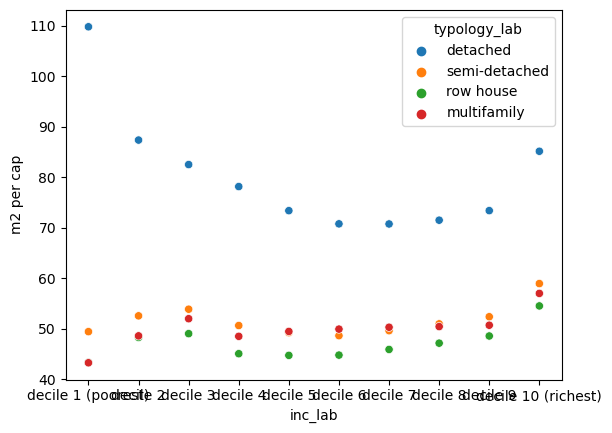

In [550]:
use_m2_total_inc = (use['size'+year+'_w1']*use['n_hhd']).groupby(level=[0,1], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc = use['n_hhdmem'+year].groupby(level=[0,1], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group
use_m2_per_cap_inc
df_plot = use_m2_per_cap_inc.rename('m2 per cap').reset_index()
sns.scatterplot(x='inc_lab', y='m2 per cap', data=df_plot, hue='typology_lab')
"""interpretation: whether people live in a detached or multi-dwelling building is more indicative of the floor area per capita than their income; the higher floor area among the higher income deciles seems to be related to the type of building people live in rather than affording larger dwellings in the same category of building"""
#TODO: plot this as bubble plot with size of dot indicating number of households or people in each group

'interpretation: whether people live on the countryside or urban seems to be more indicative for floor area than the income group, although the income group also follows a surprisingly coherent pattern across the urban-rural gradient'

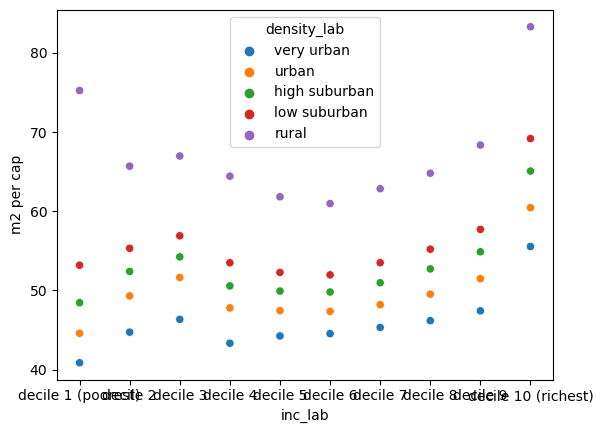

In [551]:
use_m2_total_inc = (use['size'+year+'_w1']*use['n_hhd']).groupby(level=[0,3], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc = use['n_hhdmem'+year].groupby(level=[0,3], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group
use_m2_per_cap_inc
df_plot = use_m2_per_cap_inc.rename('m2 per cap').reset_index()
sns.scatterplot(x='inc_lab', y='m2 per cap', data=df_plot, hue='density_lab')
"""interpretation: whether people live on the countryside or urban seems to be more indicative for floor area than the income group, although the income group also follows a surprisingly coherent pattern across the urban-rural gradient"""

'building type seems to be more indicative of floor area than the urban-rural gradient, although rural is in each category more floor space intensive than urban buildings of the same type'

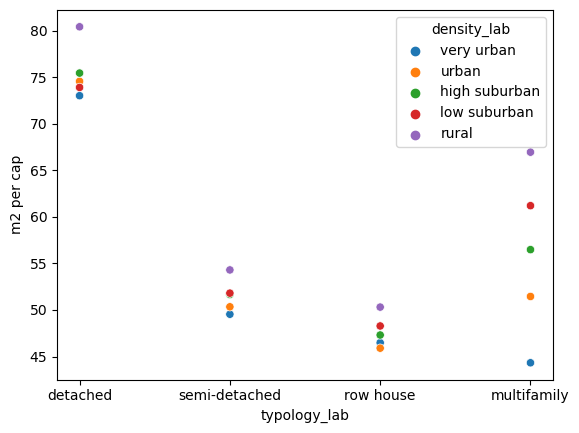

In [552]:
use_m2_total_inc = (use['size'+year+'_w1']*use['n_hhd']).groupby(level=[1,3], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc = use['n_hhdmem'+year].groupby(level=[1,3], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group
use_m2_per_cap_inc
df_plot = use_m2_per_cap_inc.rename('m2 per cap').reset_index()
sns.scatterplot(x='typology_lab', y='m2 per cap', data=df_plot, hue='density_lab')
"""building type seems to be more indicative of floor area than the urban-rural gradient, although rural is in each category more floor space intensive than urban buildings of the same type"""

'similar to urban-rural'

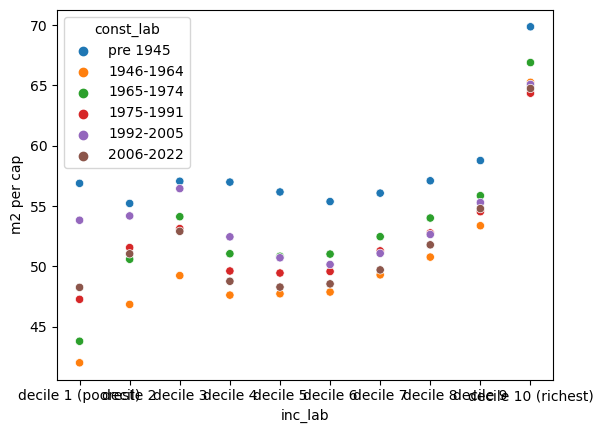

In [553]:
use_m2_total_inc = (use['size'+year+'_w1']*use['n_hhd']).groupby(level=[0,2], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc = use['n_hhdmem'+year].groupby(level=[0,2], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group
use_m2_per_cap_inc
df_plot = use_m2_per_cap_inc.rename('m2 per cap').reset_index()
sns.scatterplot(x='inc_lab', y='m2 per cap', data=df_plot, hue='const_lab')
"""similar to urban-rural"""

<AxesSubplot: xlabel='typology_lab', ylabel='m2 per cap'>

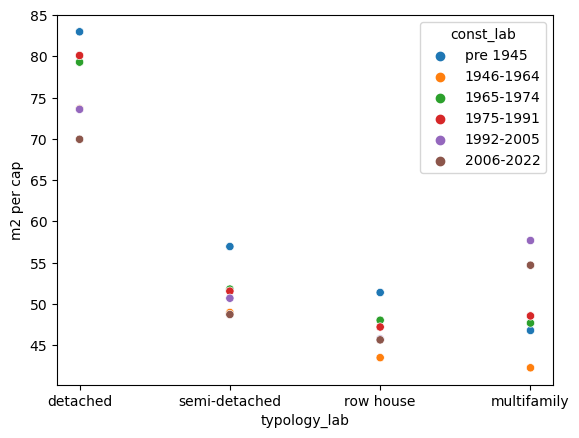

In [554]:
use_m2_total_inc = (use['size'+year+'_w1']*use['n_hhd']).groupby(level=[1,2], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc = use['n_hhdmem'+year].groupby(level=[1,2], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group
use_m2_per_cap_inc
df_plot = use_m2_per_cap_inc.rename('m2 per cap').reset_index()
sns.scatterplot(x='typology_lab', y='m2 per cap', data=df_plot, hue='const_lab')

#### Gas / space heating

In [555]:
bubblechart((use['gas'+year]*use['n_hhd']), use['n_hhdmem'+year], use['n_hhd'], 0, 1, 'GJ gas use per capita per year','equivalized income level', 'GJ_per_cap_inc_type')

'interpretation: especially the highest income decile has considerably more gas consumption per capita than the vast majority'

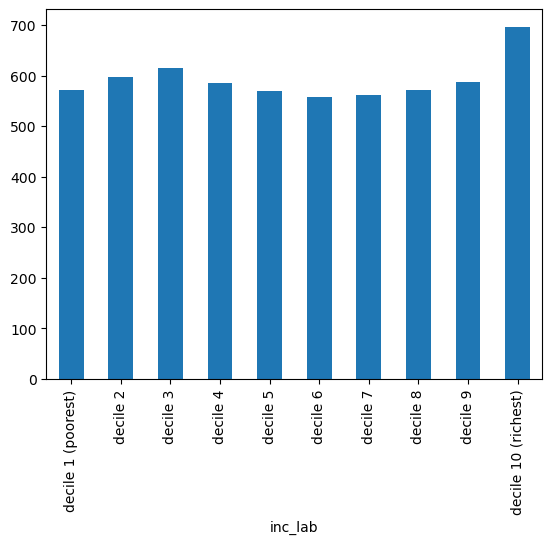

In [556]:
use_m2_total_inc = (use['gas'+year]*use['n_hhd']).groupby(level=0, sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc = use['n_hhdmem'+year].groupby(level=0, sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group
use_m2_per_cap_inc.plot(kind='bar') #per person
"""interpretation: especially the highest income decile has considerably more gas consumption per capita than the vast majority"""

In [557]:
bubblechart((use['netelectricity'+year]*use['n_hhd']), use['n_hhdmem'+year], use['n_hhd'], 0, 2, 'kWh electricity use per capita per year','equivalized income level', 'kWh_per_cap_inc_age')


In [558]:
((use['netelectricity'+year]*use['n_hhd'])/use['n_hhdmem'+year]).sort_values(ascending=False).head(30)

inc_lab              typology_lab  const_lab  density_lab    distance_train_lab
decile 1 (poorest)   detached      pre 1945   very urban     4nd quintile         2,793.84
decile 4             detached      1975-1991  very urban     3nd quintile         2,657.21
decile 1 (poorest)   detached      1965-1974  very urban     2nd quintile         2,464.53
decile 2             detached      1946-1964  very urban     2nd quintile         2,424.05
decile 1 (poorest)   detached      1946-1964  very urban     nearest quintile     2,305.90
decile 4             detached      1992-2005  very urban     3nd quintile         2,268.88
decile 1 (poorest)   detached      1946-1964  high suburban  3nd quintile         2,234.27
                                   1965-1974  urban          nearest quintile     2,215.84
                                   1946-1964  very urban     2nd quintile         2,186.69
                                   2006-2022  urban          2nd quintile         2,164.44
decile 10 

In [559]:
((use['netelectricity'+year]*use['n_hhd'])/use['n_hhdmem'+year]).sort_values(ascending=True).head(30)

inc_lab              typology_lab   const_lab  density_lab   distance_train_lab
decile 4             row house      2006-2022  very urban    furthest quintile    619.07
decile 5             row house      2006-2022  very urban    furthest quintile    640.63
                     semi-detached  2006-2022  rural         nearest quintile     665.79
decile 9             multifamily    1965-1974  rural         2nd quintile         696.23
decile 6             detached       2006-2022  very urban    2nd quintile         698.02
decile 8             semi-detached  2006-2022  very urban    furthest quintile    726.73
decile 6             semi-detached  2006-2022  rural         nearest quintile     738.57
decile 5             row house      2006-2022  very urban    4nd quintile         738.62
decile 8             row house      2006-2022  very urban    furthest quintile    739.36
decile 3             row house      2006-2022  very urban    3nd quintile         741.06
                              

#### Mobility

In [560]:
bubblechart((use['car_pkm']*use['n_hhd']/365), use['n_hhdmem'+year], use['n_hhd'], 0, 3, 'pkm car use per capita per day','equivalized income level', 'pkmcar_per_cap_inc_urb')

In [561]:
((use['car_pkm']*use['n_hhd']/365)/use['n_hhdmem'+year]).sort_values(ascending=False).head(60)

inc_lab              typology_lab   const_lab  density_lab    distance_train_lab
decile 9             multifamily    2006-2022  rural          nearest quintile     103.01
                                    1992-2005  rural          nearest quintile      95.09
                                    1946-1964  rural          nearest quintile      94.43
                     semi-detached  1975-1991  rural          nearest quintile      93.72
                     row house      2006-2022  rural          nearest quintile      93.20
                                    1975-1991  rural          nearest quintile      91.57
                                    pre 1945   rural          nearest quintile      91.57
                     detached       pre 1945   rural          nearest quintile      89.35
                                    1965-1974  rural          nearest quintile      89.02
                                    1975-1991  rural          nearest quintile      88.93
                   

In [562]:
((use['car_hhd']*use['n_hhd']/365)/use['n_hhdmem'+year]).sort_values(ascending=True).head(30)

inc_lab             typology_lab   const_lab  density_lab  distance_train_lab
decile 1 (poorest)  row house      1975-1991  very urban   furthest quintile    0.00
                    semi-detached  1975-1991  very urban   furthest quintile    0.00
                    row house      1965-1974  very urban   furthest quintile    0.01
                    multifamily    1946-1964  very urban   furthest quintile    0.01
                                   1965-1974  very urban   furthest quintile    0.01
                    semi-detached  1965-1974  very urban   furthest quintile    0.01
                    multifamily    1975-1991  very urban   furthest quintile    0.01
                                   pre 1945   very urban   furthest quintile    0.01
                    row house      pre 1945   very urban   furthest quintile    0.01
                    semi-detached  1946-1964  very urban   furthest quintile    0.01
                    row house      1946-1964  very urban   furthest quin

In [563]:
bubblechart((use['transit_pkm']*use['n_hhd']/365), use['n_hhdmem'+year], use['n_hhd'], 0, 4, 'pkm transit use per capita per day','equivalized income level', 'pkmtrain_per_cap_inc_dist')

In [564]:
bubblechart((use['cycle_pkm']*use['n_hhd']/365), use['n_hhdmem'+year], use['n_hhd'], 0, 3, 'km bicycle use per capita per day','equivalized income level', 'pkmbike_per_cap_inc_urb')

In [565]:
bubblechart((use['walk_pkm']*use['n_hhd']/365), use['n_hhdmem'+year], use['n_hhd'], 0, 4, 'km walking per capita per day','equivalized income level', 'pkmwalk_per_cap_inc_dist')

In [566]:
bubblechart((use['distance_depstore'+year]*use['n_hhd']), use['n_hhd'], use['n_hhd'], 0, 3, 'distance to department store','equivalized income level', 'distance_to_departmentstore_inc_urb')

In [567]:
bubblechart((use['distance_depstore'+year]*use['n_hhd']), use['n_hhd'], use['n_hhd'], 3, 0, 'distance to department store [m]','urbanity', 'distance_to_departmentstore_urb_inc', bubblecolors=px.colors.sequential.Plasma_r)

In [568]:
bubblechart((use['distance_supermarket'+year]*use['n_hhd']), use['n_hhd'], use['n_hhd'], 3, 0, 'distance to supermarket [m]','urbanity', 'distance_to_supermarket_urb_inc', bubblecolors=px.colors.sequential.Plasma_r)

In [569]:
bubblechart((use['distance_middleschool'+year]*use['n_hhd']), use['n_hhd'], use['n_hhd'], 3, 0, 'distance to middleschool [m]','urbanity', 'distance_to_middleschool_urb_inc', bubblecolors=px.colors.sequential.Plasma_r)

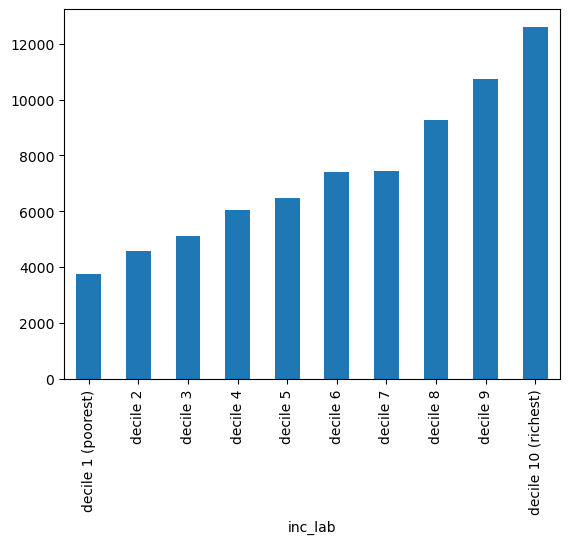

In [570]:
#floor area per income level
use_m2_total_inc = (use['car_pkm']*use['n_hhd']).groupby(level=0, sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc = use['n_hhdmem'+year].groupby(level=0, sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group
use_m2_per_cap_inc.plot(kind='bar') #per person
"""interpretation: especially the highest income decile has considerably more floor area available than the vast majority"""

#floor area per income level and urbanisation type
use_m2_total_inc_type = (use['car_pkm']*use['n_hhd']).groupby(level=[0,3], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc_type = use['n_hhdmem'+year].groupby(level=[0,3], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc_type = use_m2_total_inc_type / use_cap_total_inc_type #m2/cap in each income group

#preparing the dataframes for plotting
df = use_m2_per_cap_inc
df2=use_m2_per_cap_inc_type.rename('value').to_frame()
df2['n_hhd'] = use['n_hhd'].groupby(level=[0,3], sort=False).sum()

#plot
colors = ['#000000', #construction
                            '#fe6100', #buildings                                              
                                        '#648fff', #roads
                                        '#785ef0', #railways
                                        '#ffb000', #electricity
                                        '#808080', #other civil engineering
                                        '#000000', #construction
                                        ]
fig = px.bar(df, x=df.values, y=df.index,  
             labels={'x':'pkm car travel per capita', 'inc_lab':'household income level'}, 
             template='simple_white', 
             color_discrete_sequence=colors) 
fig.update_layout(width=1000, height=500, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=18),
                      bargap=0.9,
                      legend=dict(
        orientation="h",
        #entrywidth=70,
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25,
    ))



for i in df2.index.levels[1].to_list():
    df_plot = df2.xs(i, level=1)
    fig.add_trace(go.Scatter(
            y=df_plot.index, 
            x=df_plot['value'],
            mode='markers',
            name=i,
            marker=dict(size=df_plot['n_hhd'],
                        sizemode='area',
                        sizeref=4*max(df2['n_hhd'])/(40.**2),
                        sizemin=4,
                        #color=10*[0, 1, 2, 3],
                        ),
            showlegend=True
        ))

fig.write_image('visualisations/bubblechart_carpkm_per_cap_inc_urb'+year+'.png', scale=3)
fig.show()

'population density seems to be more indicative of car travel than the building type, although detached buildings are in each category more car travel intensive than multi-dwelling buildings of the same location'

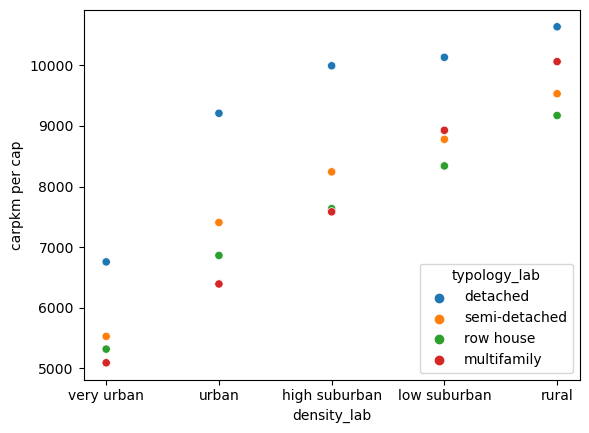

In [571]:
use_m2_total_inc = (use['car_pkm']*use['n_hhd']).groupby(level=[1,3], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc = use['n_hhdmem'+year].groupby(level=[1,3], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group
use_m2_per_cap_inc
df_plot = use_m2_per_cap_inc.rename('carpkm per cap').reset_index()
sns.scatterplot(x='density_lab', y='carpkm per cap', data=df_plot, hue='typology_lab')
"""population density seems to be more indicative of car travel than the building type, although detached buildings are in each category more car travel intensive than multi-dwelling buildings of the same location"""

'the distance to the train station especially matters for car travel in rural and suburban areas, so low-density areas that are close to a train station have even lower car travel than urban areas that are close to such a station, whereas urban areas that are far from a train station still have low car travel'

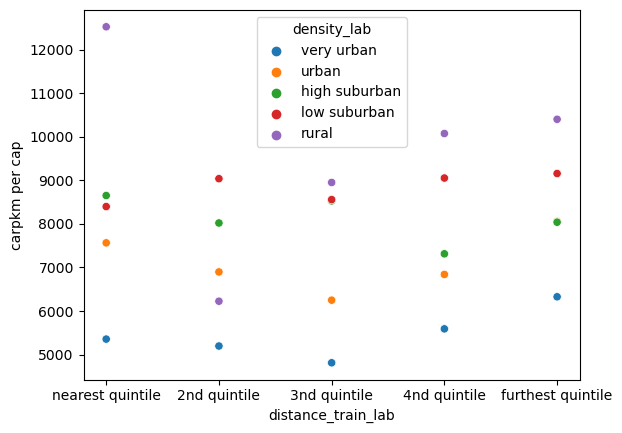

In [572]:
use_m2_total_inc = (use['car_pkm']*use['n_hhd']).groupby(level=[3,4], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc = use['n_hhdmem'+year].groupby(level=[3,4], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group
use_m2_per_cap_inc
df_plot = use_m2_per_cap_inc.rename('carpkm per cap').reset_index()
sns.scatterplot(x='distance_train_lab', y='carpkm per cap', data=df_plot, hue='density_lab')
"""the distance to the train station especially matters for car travel in rural and suburban areas, so low-density areas that are close to a train station have even lower car travel than urban areas that are close to such a station, whereas urban areas that are far from a train station still have low car travel"""

### Building Construction
- translate floor space to BONSAI material categories
- include material use for maintenance
- normalise impact to annual using building lifetime

In [573]:
# Loading the material intensities per floor area
if material_buildings_source == "Oorschot-MPG": #kg/m2
    mi_buildings = pd.read_excel(
        "data_input/MI_Buildings_Oorschot2023MetabolicMPG.xlsx",
        sheet_name="Building_MI",
        index_col=[0, 1],
        header=[0, 1], skiprows=3
    ).drop("2018-2050", axis=0, level=1)
    mi_buildings.index.names = ["Building type", "Cohort"]
    mi_buildings.columns.names = ["BONSAI", "Material"]
    mi_buildings.fillna(0, inplace=True)
elif material_buildings_source == "Oorschot": #kg/m2
    mi_buildings = pd.read_excel(
        "data_input/MI_Buildings_Oorschot2023.xlsx",
        sheet_name="mi_pre2018",
        index_col=[0, 1],
        header=[0, 1],
    ).droplevel(1, axis=1)
    mi_buildings.index.names = ["Building type", "Cohort"]
    mi_buildings.columns.name = "Material"

    #converting the material intensities to BONSAI material categories
    mi_buildings_insulation_share = pd.read_excel(
            "data_input/MI_Buildings_Oorschot2023.xlsx",
            sheet_name="Share_of_insulation_materials",
            index_col=[0, 1],
            header=[0],
            skipfooter=3,
        ).drop("Unnamed: 8", axis=1)
    for i in mi_buildings_insulation_share.columns:
        mi_buildings[i] = (
            mi_buildings["Insulation"] * mi_buildings_insulation_share[i].iloc[0]
            )

    mi_buildings = (
            mi_buildings
            .T.groupby(level=0)
            .sum()
            .T.sort_index()
            .replace(0, np.nan)
            .dropna(how="all", axis=1)
            .drop("Insulation", axis=1)
        )
    # matching material names
    replacement_map = {'Bitumen':'Bitumen', #soon
                        'Brick':'Ceramics', #BRIK,
                        'Clay brick':'Ceramics', #BRIK
                        'Ceramics':'Ceramics', #BRIK (bricks, tiles, construction products)
                        'Sand-lime brick':'Ceramics', #BRIK
                        'Sand':'Sand', #SDCL
                        'Concrete':'Concrete', #CMNT (only lime,cement and plast, no mix)
                        'Mortal':'Mortar', #CMNT
                        'Gypsum':'Mortar', #CMNT (plaster of gypsum)
                        'Aluminum':'Aluminium', #ALUM
                        'Copper':'Copper', #COPP
                        'Other metals':'Other metals', #ONFM
                        'Electronics':'Electronics', #ELMA
                        'Glass':'Glass', #GLAS 
                        'Glass wool':'Glass', #GLAS (includes explicitely glass wool)
                        'Stone wool':'Mineral wool', #ONMM (includes explicitely mineral wool)
                        'Iron & steel':'Steel', #STEL or FABM
                        'Steel':'Steel', #STEL or FABM
                        'Other biobased materials':'Wood and straw', #WOOD
                        'Wood':'Wood and straw', #WOOD
                        'Other construction materials':'Other construction material', #ONMM, could also be STON, SDCL or CMNT
                        'Other':'Adhesives and paint', #could be CHEM, PLAS, PAPE, ELMA
                        'Paper':'Paper', #PAPE 
                        'Expanded polystyrene':'Plastic', #RUBP 
                        'Extruded polystyrene':'Plastic', #RUBP
                        'Plastic':'Plastic', #RUBP
                        'Plastics':'Plastic', #RUBP
                        'Polyurethanes':'Plastic', #RUBP
                        'Adhesives & paint':'Adhesives and paint', #CHEM (other chemical products, for glues) or PLAS (basic plastics) 
                        'Stone':'Stone', #STON
                        }

    mi_buildings = mi_buildings.stack().reset_index()
    mi_buildings['Material_group'] = mi_buildings['Material'].map(replacement_map)
    mi_buildings = mi_buildings.drop('Material', axis=1).groupby(['Building type', 'Cohort', 'Material_group']).sum().unstack().droplevel(0, axis=1)

    #selecting only residential buildings
    mi_buildings.drop(['industry', 'office', 'services', 'shop'], axis=0, level=0, inplace=True)




In [574]:
# visualisation of the assumed material intensities
""" the trend shows a shift from wood to brick and concrete"""
m_plot = mi_buildings.copy()
m_plot = m_plot.rename(index={'pre 1945':'1000-1945'})
if material_buildings_source == "Oorschot-MPG":
    m_plot = m_plot.groupby(axis=1, level=0).sum()
m_plot.index = [str(i) + ' ' + str(j) for i, j in m_plot.index]
m_plot = m_plot.stack().reset_index()
m_plot.columns = ['building', 'material', 'value']
fig = px.bar(m_plot, x='value', y='building', color='material', labels={'value':'material intensity per floor area [kg/m2]'}, template='simple_white', 
             color_discrete_sequence= px.colors.qualitative.Prism) #antique, vivid, prism, T10
fig.update_layout(width=1100, height=500, yaxis = dict(autorange="reversed"))    
fig.write_image('visualisations/mi_buildings'+material_buildings_source+'_grouped.svg')
fig.show()

In [575]:
#calculating the material contained in an average dwelling per category
mi_buildings.index = mi_buildings.index.rename(['typology_lab', 'const_lab']) # kg/m2 ufa
use_m2 = use['size'+year+'_w1'].reorder_levels(['typology_lab', 'const_lab', 'inc_lab', "density_lab", "distance_train_lab"]) #m2 ufa / dwelling
use_m2 = pd.concat([use_m2] * len(mi_buildings.columns), axis=1)
use_m2.columns = mi_buildings.columns
material_buildings = use_m2.multiply(mi_buildings.reindex(use_m2.index), level=[0,1]) #kg / dwelling

In [576]:
material_buildings #kg / dwelling

BONSAI                                                                               M_ALUM  \
Material                                                                  Aluminium (kg/m2)   
typology_lab const_lab inc_lab             density_lab distance_train_lab                     
detached     pre 1945  decile 1 (poorest)  very urban  nearest quintile                 NaN   
                                                       2nd quintile                     NaN   
                                                       3nd quintile                     NaN   
                                                       4nd quintile                     NaN   
                                                       furthest quintile                NaN   
...                                                                                     ...   
multifamily  2006-2022 decile 10 (richest) rural       nearest quintile                 NaN   
                                                       2nd quintile                     NaN   
                                                       3nd quintile                     NaN   
                                                       4nd quintile                     NaN   
                                                       furthest quintile                NaN   

BONSAI                                                                              M_BRIK  \
Material                                                                  Baksteen (kg/m2)   
typology_lab const_lab inc_lab             density_lab distance_train_lab                    
detached     pre 1945  decile 1 (poorest)  very urban  nearest quintile                NaN   
                                                       2nd quintile                    NaN   
                                                       3nd quintile                    NaN   
                                                       4nd quintile                    NaN   
                                                       furthest quintile               NaN   
...                                                                                    ...   
multifamily  2006-2022 decile 10 (richest) rural       nearest quintile                NaN   
                                                       2nd quintile                    NaN   
                                                       3nd quintile                    NaN   
                                                       4nd quintile                    NaN   
                                                       furthest quintile               NaN   

BONSAI                                                                    M_CMNT + M_SDCL  \
Material                                                                    Beton (kg/m2)   
typology_lab const_lab inc_lab             density_lab distance_train_lab                   
detached     pre 1945  decile 1 (poorest)  very urban  nearest quintile               NaN   
                                                       2nd quintile                   NaN   
                                                       3nd quintile                   NaN   
                                                       4nd quintile                   NaN   
                                                       furthest quintile              NaN   
...                                                                                   ...   
multifamily  2006-2022 decile 10 (richest) rural       nearest quintile               NaN   
                                                       2nd quintile                   NaN   
                                                       3nd quintile                   NaN   
                                                       4nd quintile                   NaN   
                                                       furthest quintile              NaN   

BONSAI                                           

#### Environmental Footprint

In [577]:
# File import
mult_bonsai = pd.read_csv('data_input/240605_BONSAI_ghg_for_all_iluc.csv', index_col=[0,1,2,3], header=[0], skipfooter=9) # kg CO2eq. per kg material

#selecting relevant product codes
prod_codes = material_buildings.columns.levels[0].to_list()
prod_codes.append('M_CMNT')
mult_bonsai = mult_bonsai[mult_bonsai.index.get_level_values(0).isin(prod_codes)] 
mult_bonsai = mult_bonsai.droplevel([1,2,3])
mult_bonsai = mult_bonsai[['NL']] #select only NL market

#calculating environmental impacts of composite material concrete
concrete_cement_pc = 0.35 #based on M20 and M25 concrete grade
mult_bonsai.loc['M_CMNT + M_SDCL'] = mult_bonsai.loc[['M_CMNT']].squeeze()*concrete_cement_pc + mult_bonsai.loc[['M_SDCL']].squeeze()*(1-concrete_cement_pc)

mult_bonsai # kg CO2eq. per kg material

/var/folders/__/twfrdq8n75n5f0118_f882700000gn/T/ipykernel_79287/1297572943.py:2: ParserWarning:

Falling back to the 'python' engine because the 'c' engine does not support skipfooter; you can avoid this warning by specifying engine='python'.



,NL
Exio prod code,
M_STON,0.00
M_SDCL,0.00
M_WOOD,0.89
M_PAPE,2.43
M_BITU,1.79
M_CHEM,1.06
M_RUBP,3.79
M_GLAS,1.29
M_BRIK,0.18


In [578]:
# calculating embodied GHG emissions of materials in buildings
material_buildings_grouped = material_buildings.groupby(axis=1, level=0).sum() #kg/dwelling
ghg_material_buildings = material_buildings_grouped.multiply(mult_bonsai.iloc[:,0], axis=1).dropna(axis=1, how='all') #kg CO2eq. / dwelling

ghg_material_buildings #kg CO2eq/dwelling

M_ALUM  \
typology_lab const_lab inc_lab             density_lab distance_train_lab           
detached     pre 1945  decile 1 (poorest)  very urban  nearest quintile      0.00   
                                                       2nd quintile          0.00   
                                                       3nd quintile          0.00   
                                                       4nd quintile          0.00   
                                                       furthest quintile     0.00   
...                                                                           ...   
multifamily  2006-2022 decile 10 (richest) rural       nearest quintile      0.00   
                                                       2nd quintile          0.00   
                                                       3nd quintile          0.00   
                                                       4nd quintile          0.00   
                                                       furthest quintile     0.00   

                                                                           M_BITU  \
typology_lab const_lab inc_lab             density_lab distance_train_lab           
detached     pre 1945  decile 1 (poorest)  very urban  nearest quintile      0.00   
                                                       2nd quintile          0.00   
                                                       3nd quintile          0.00   
                                                       4nd quintile          0.00   
                                                       furthest quintile     0.00   
...                                                                           ...   
multifamily  2006-2022 decile 10 (richest) rural       nearest quintile      0.00   
                                                       2nd quintile          0.00   
                                                       3nd quintile          0.00   
                                                       4nd quintile          0.00   
                                                       furthest quintile     0.00   

                                                                           M_BRIK  \
typology_lab const_lab inc_lab             density_lab distance_train_lab           
detached     pre 1945  decile 1 (poorest)  very urban  nearest quintile      0.00   
                                                       2nd quintile          0.00   
                                                       3nd quintile          0.00   
                                                       4nd quintile          0.00   
                                                       furthest quintile     0.00   
...                                                                           ...   
multifamily  2006-2022 decile 10 (richest) rural       nearest quintile      0.00   
                                                       2nd quintile          0.00   
                                                       3nd quintile          0.00   
                                                       4nd quintile          0.00   
                                                       furthest quintile     0.00   

                                                                           M_CHEM  \
typology_lab const_lab inc_lab             density_lab distance_train_lab           
detached     pre 1945  decile 1 (poorest)  very urban  nearest quintile      0.00   
                                                       2nd quintile          0.00   
                                                       3nd quintile          0.00   
                                                       4nd quintile          0.00   
                                                       furthest quintile     0.00   
...                                                                           ...   
multifamily  2006-2022 decile 10 (richest) rural       nearest quintile      

In [579]:
ghg_material_buildings.sum(1) #total GHG emission per dwelling

typology_lab  const_lab  inc_lab              density_lab  distance_train_lab
detached      pre 1945   decile 1 (poorest)   very urban   nearest quintile     0.00
                                                           2nd quintile         0.00
                                                           3nd quintile         0.00
                                                           4nd quintile         0.00
                                                           furthest quintile    0.00
                                                                                ... 
multifamily   2006-2022  decile 10 (richest)  rural        nearest quintile     0.00
                                                           2nd quintile         0.00
                                                           3nd quintile         0.00
                                                           4nd quintile         0.00
                                                           furthest quin

### Building Use Phase
- translate district heating to BONSAI fuel categories
- translate solar PV and heat pumps to BONSAI material categories
- harmonise labels for electricity and gas use with BONSAI categories

#### Electricity

In [580]:
# File import
mult_bonsai = pd.read_csv('data_input/240605_BONSAI_ghg_for_all_iluc.csv', index_col=[0,1,2,3], header=[0], skipfooter=9).droplevel([1,2,3]) # tonne CO2eq. per TJ electricity
mult_bonsai = mult_bonsai['NL'] #select only NL market

electricity_buildinguse = use['netelectricity'+year] #kWh per household per year
electricity_buildinguse = electricity_buildinguse * 3.6 #MJ per household per year
electricity_buildinguse = electricity_buildinguse /1e6 #TJ per household per year
ghg_electricity_buildinguse = electricity_buildinguse * mult_bonsai.loc['M_electricity'] * 1000 #kg CO2eq. per household per year

/var/folders/__/twfrdq8n75n5f0118_f882700000gn/T/ipykernel_79287/1083587744.py:2: ParserWarning:

Falling back to the 'python' engine because the 'c' engine does not support skipfooter; you can avoid this warning by specifying engine='python'.



In [581]:
ghg_electricity_buildinguse #annual GHG emission per household

inc_lab              typology_lab  const_lab  density_lab  distance_train_lab
decile 1 (poorest)   detached      pre 1945   very urban   nearest quintile     1,610.11
                                                           2nd quintile         1,584.24
                                                           3nd quintile         1,548.15
                                                           4nd quintile         2,247.09
                                                           furthest quintile         NaN
                                                                                  ...   
decile 10 (richest)  multifamily   2006-2022  rural        nearest quintile     1,555.22
                                                           2nd quintile         1,307.62
                                                           3nd quintile         1,397.76
                                                           4nd quintile         1,360.08
                                

#### Gas

In [582]:
#M_GASE upstream emissions of natural gas per tonne
#EF_GASE combustion of natural gas per TJ
gas_buildinguse = use['gas'+year] #m3 per household per year
gas_buildinguse_tonne = gas_buildinguse * 0.735 #kg per household per year
ghg_gas_buildinguse_footprint = gas_buildinguse_tonne * mult_bonsai.loc['M_GASE'] #kg CO2eq. per household per year
gas_buildinguse_GJ = gas_buildinguse * 0.0316 #GJ per household per year
ghg_gas_buildinguse_direct = gas_buildinguse_GJ * mult_bonsai.loc['EF_GASE'] #kg CO2eq. per household per year
ghg_gas_buildinguse = ghg_gas_buildinguse_footprint + ghg_gas_buildinguse_direct

In [583]:
ghg_gas_buildinguse #annual GHG emission per household

inc_lab              typology_lab  const_lab  density_lab  distance_train_lab
decile 1 (poorest)   detached      pre 1945   very urban   nearest quintile     5,123.45
                                                           2nd quintile         5,339.05
                                                           3nd quintile         5,404.29
                                                           4nd quintile         6,155.29
                                                           furthest quintile         NaN
                                                                                  ...   
decile 10 (richest)  multifamily   2006-2022  rural        nearest quintile     1,947.86
                                                           2nd quintile         2,701.50
                                                           3nd quintile         2,308.10
                                                           4nd quintile         2,536.70
                                

#### Other space heating (heat pump, district heating)

In [584]:
heatpump_buildings = use['n_heatpump'+year]/use['n_hhd'] #mean number of heatpumps per household
ghg_heatpump_buildings = heatpump_buildings * 386 #kg CO2e per heat pump (10kW) according to Verhagen et al.,  in ecoinvent 1445 #TODO:remove info that this is from ecoinv

In [585]:
ghg_heatpump_buildings #total GHG emission per household

inc_lab              typology_lab  const_lab  density_lab  distance_train_lab
decile 1 (poorest)   detached      pre 1945   very urban   nearest quintile       NaN
                                                           2nd quintile           NaN
                                                           3nd quintile           NaN
                                                           4nd quintile           NaN
                                                           furthest quintile      NaN
                                                                                 ... 
decile 10 (richest)  multifamily   2006-2022  rural        nearest quintile       NaN
                                                           2nd quintile           NaN
                                                           3nd quintile           NaN
                                                           4nd quintile           NaN
                                                           fur

In [586]:
#File import
district_heating = pd.read_excel(
    "data_input/District-Heating-Dataset.xlsx",
    sheet_name = "National average",
    header=[0],
)
district_heating.set_index('Heat_Source', inplace=True)

energy_districtheating = use['n_cityheating'+year]*use['warmteschatting_SW'] / use['n_hhd'] #GJ heat delivered per household per year
energy_districtheating = energy_districtheating * 1.32 #GJ generated pre-distribution, assuming 24% heat loss in high-temperature district heating networks cf. Lund et al. (2014). 4th Generation district heating (4GDH): Integrating smart thermal grids into future sustainable energy systems. Energy, 68, 1–11. https://doi.org/10.1016/j.energy.2014.02.089

energy_districtheating_dict = {}
for i in district_heating.index:
    energy_districtheating_dict[i] = energy_districtheating * district_heating.loc[i, 'Share'] *  district_heating.loc[i, 'kg CO2 per GJ'] #kg CO2e of GJ
    
#ghg_heat_districtheating = energy_districtheating * mult_bonsai['M_heat_HOUS'] #kg CO2eq. per household per year
ghg_heat_districtheating = sum(energy_districtheating_dict.values())

ghg_heat_districtheating

inc_lab              typology_lab  const_lab  density_lab  distance_train_lab
decile 1 (poorest)   detached      pre 1945   very urban   nearest quintile     NaN
                                                           2nd quintile         NaN
                                                           3nd quintile         NaN
                                                           4nd quintile         NaN
                                                           furthest quintile    NaN
                                                                                 ..
decile 10 (richest)  multifamily   2006-2022  rural        nearest quintile     NaN
                                                           2nd quintile         NaN
                                                           3nd quintile         NaN
                                                           4nd quintile         NaN
                                                           furthest quintile    Na

#### Electricity generation technology

In [587]:
capacity_photovoltaic = use['solarcapacity'+year] #kWp PV per household (including households with and without) 
ghg_material_photovoltaic = capacity_photovoltaic/3 * 6313 #kg CO2eq. per household #TODO:remove info that this is from ecoinv

In [588]:
(use['solarcapacity'+year]*use['n_hhd']/(use['n_solar'+year].fillna(2.5)))/ 3 #kWp per household with 

inc_lab              typology_lab  const_lab  density_lab  distance_train_lab
decile 1 (poorest)   detached      pre 1945   very urban   nearest quintile     0.36
                                                           2nd quintile         1.97
                                                           3nd quintile         3.68
                                                           4nd quintile         0.00
                                                           furthest quintile     NaN
                                                                                ... 
decile 10 (richest)  multifamily   2006-2022  rural        nearest quintile     0.00
                                                           2nd quintile         1.34
                                                           3nd quintile         1.37
                                                           4nd quintile         1.39
                                                           furthest quin

### Mobility
- add pkm and cars to use data
- translate pkm to BONSAI fuel categories
- translate pkm to infrastructure demand to BONSAI material categories
- normalise cars to annual cars using car lifetime
- harmonise labels for cars with BONSAI categories

In [589]:
#TODO: update emission factors below to NL context (these are currently sourced from Allekotte et al. 2020 for German context) #data also allows for distinguishing use phase, infrastructure and vehicle emission 
#ghg_car_mobilityuse = use['car_pkm']*158/1000 #kg CO2eq. per household per year (including use phase, infrastructure; excluding: vehicle production)
ghg_car_mobilityuse = use['car_pkm']*0.36599 #kg CO2eq (including use phase, infrastructure and vehicle production); Ecoinvent (market for transport, passenger car, Europe (RER)); CMLv4.8 2016
ghg_car_vehicle = use['car_hhd']*mult_bonsai.loc['M_auto']*1000 #kg CO2eq. per household per year
ghg_transit_mobilityuse = (use['transit_pkm']*0.7)*0.044621 + (use['transit_pkm']*0.3)*0.11334 #kg CO2eq (including use phase, infrastructure, and vehicle production); Ecoinvent (transport, passenger, train (Italy) and transport, regular bus (Switzerland)); CMLv4.8 2016
#source for ghg_transit share pkm: https://ec.europa.eu/eurostat/statistics-explained/index.php?title=File:Travel_distance_per_person_per_day_by_main_travel_mode_for_urban_mobility_on_all_days_(%25)_v3.png ; https://opendata.cbs.nl/statline/#/CBS/en/dataset/84687ENG/table 
#ghg_transit_mobilityuse = use['transit_pkm']*73/1000 #kg CO2eq. per household per year (including use phase, infrastructure and vehicle production)
#ghg_cycle_mobilityuse = use['cycle_pkm']*11/1000 #kg CO2eq. per household per year (including infrastructure and vehicle production)
ghg_cycle_mobilityuse = use['cycle_pkm']*0.0011864 #kg CO2eq (including infrastructure and vehicle produciton); Ecoinvent (transport, passenter, bicycle, Switzerland); CMLv4.8 2016

## Background System: Environmental Footprints

## GHG summary

In [590]:
#source for lifetimes: https://www.oecd-ilibrary.org/docserver/d07136f0-en.pdf?expires=1729253351&id=id&accname=guest&checksum=36E59B772FE676213DBDE7CA1CA5B3D3 
#TODO: impelemnt material specific lifetimes for the buildings to include maintenance material flows
lifetime_building = 80 #years
lifetime_photovoltaic = 30 #years
lifetime_heatpump = 20 #years
lifetime_car = 10 #years


ghg_annual = pd.concat([
    (ghg_material_buildings.sum(1)/lifetime_building).reorder_levels([2,0,1,3,4]).rename('ghg_material_buildings'), 
    (ghg_heatpump_buildings/lifetime_heatpump).rename('ghg_material_heatpump'), 
    ghg_heat_districtheating.rename('ghg_heat_districtheating'),
    ghg_gas_buildinguse.rename('ghg_gas_buildinguse'), 
    ghg_electricity_buildinguse.rename('ghg_electricity_buildinguse'), 
    (ghg_material_photovoltaic/lifetime_photovoltaic).rename('ghg_material_photovoltaic'),
    ghg_car_mobilityuse.rename('ghg_car_mobilityuse'), 
    #(ghg_car_vehicle/lifetime_car).rename('ghg_car_vehicle'),
    ghg_transit_mobilityuse.rename('ghg_transit_mobilityuse'), 
    ghg_cycle_mobilityuse.rename('ghg_cycle_mobilityuse'), 
    ], axis=1)

In [591]:
ghg_annual.sum(0)

ghg_material_buildings                 0.00
ghg_material_heatpump              1,004.42
ghg_heat_districtheating          43,527.59
ghg_gas_buildinguse           16,898,249.39
ghg_electricity_buildinguse    7,283,398.06
ghg_material_photovoltaic        208,787.59
ghg_car_mobilityuse           38,350,745.03
ghg_transit_mobilityuse        1,673,702.07
ghg_cycle_mobilityuse             20,070.82
dtype: float64

In [592]:
    df = ghg_annual.multiply(use['n_hhd'], axis=0).groupby(level=0, sort=False).sum().unstack().reset_index()
    df.columns = ['process', 'income level', 'value']

    fig = px.bar(df, x='value', y='income level',color='process', 
                 #text=df['percentage'].apply(lambda x: '{0:.1%}'.format(x)), 
                 labels={'value':'Carbon footprint of housing per year [kg CO<sub>2</sub>e]'}, 
                 template='simple_white', 
             color_discrete_sequence=['rgb(000,000,000)', #buildings                                       
                                        'rgb(204,121,167)', #hp
                                        'rgb(126,041,084)', #dh,
                                        'rgb(213,094,000)', #gas
                                        'rgb(230,159,000)', #elec
                                        'rgb(240,228,066)', #pv                                  
                                        'rgb(000,114,178)', #car
                                        'rgb(086,180,233)', #transit                                         
                                        'rgb(000,158,115)', #cycling
                                        ]) 
    #fig.update_traces(textposition='inside')
    fig.update_layout(width=1000, height=500, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=18),
                      legend=dict(
        orientation="h",
        #entrywidth=70,
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25
    ))
    fig.update_traces(marker_line_width=0)

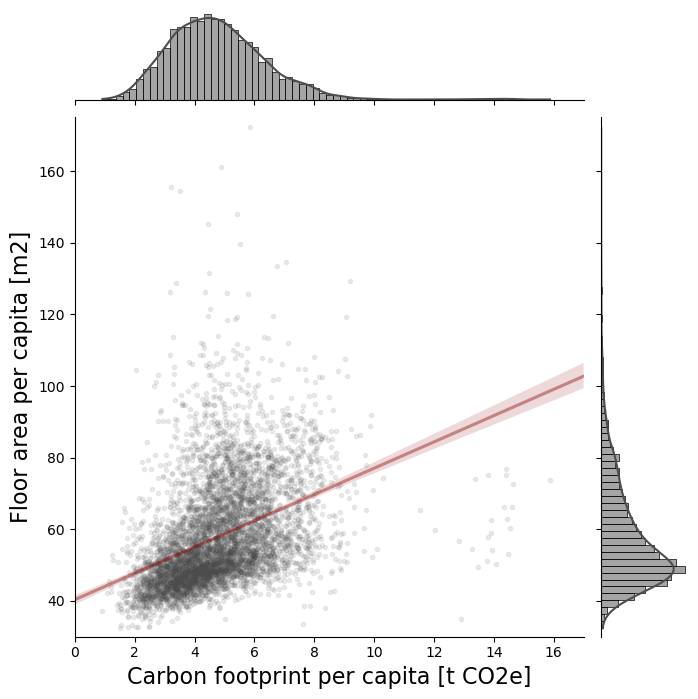

In [593]:
ghg_annual_sum = (ghg_annual.sum(1)/1000).rename('t_co2e') #t CO2e GHG emissions per household
ghg_annual_sum_m2 = pd.concat([ghg_annual_sum, use['size'+year+'_w1']], axis=1) #t CO2e GHG emissions per household AND m2 floor area per household
ghg_annual_sum_m2_cap = ghg_annual_sum_m2.multiply(use['n_hhd'], axis=0).div(use['n_hhdmem'+year], axis=0) #both per capita

g = sns.jointplot(y="size"+year+"_w1", x="t_co2e", data=ghg_annual_sum_m2_cap,
                  kind="reg", truncate=False,
                  marker='.',
                  scatter_kws={
                    "alpha": 0.1,
                    },
                  line_kws={
                      "color": "darkred",
                      "alpha": 0.4
                  },
                  xlim=(0, 17), ylim=(30, 175),
                  color="0.3", 
                  height=7,
                  )
g.set_axis_labels('Carbon footprint per capita [t CO2e]', 'Floor area per capita [m2]', fontsize=16)
g.savefig('visualisations/scatter_ghg_m2'+year+'.png')

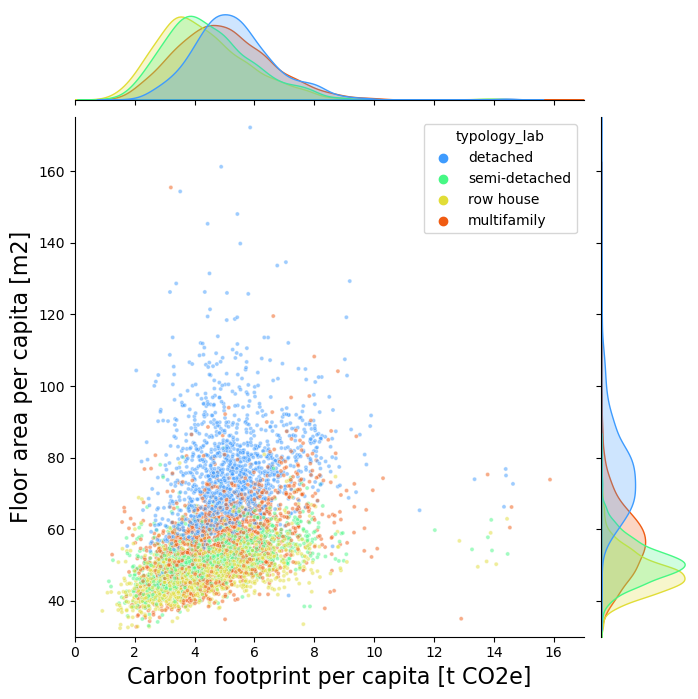

In [594]:
df = ghg_annual_sum_m2_cap.reset_index()
g = sns.jointplot(y="size"+year+"_w1", x="t_co2e", hue='typology_lab', data=df,
                  #kind="kde", truncate=False,
                  marker='.',
                  joint_kws={"alpha": 0.5},
                  palette='turbo',
                  #line_kws={"color": "darkred","alpha": 0.4},
                  xlim=(0, 17), ylim=(30, 175),
                  color="0.3", 
                  height=7,
                  )
g.set_axis_labels('Carbon footprint per capita [t CO2e]', 'Floor area per capita [m2]', fontsize=16)
g.savefig('visualisations/scatter_ghg_m2_type'+year+'.png')

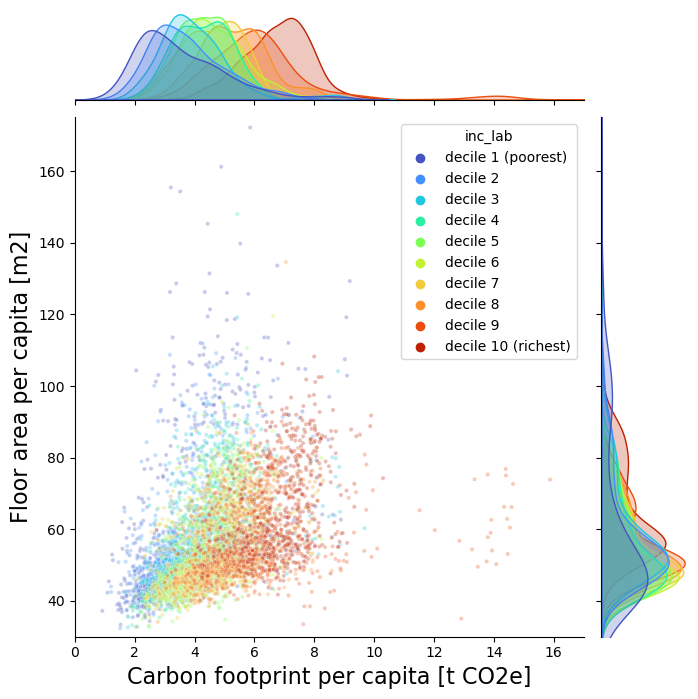

In [595]:
df = ghg_annual_sum_m2_cap.reset_index()
g = sns.jointplot(y="size"+year+"_w1", x="t_co2e", hue='inc_lab', data=df,
                  #kind="kde", truncate=False,
                  marker='.',
                  joint_kws={"alpha": 0.3},
                  palette='turbo',
                  #line_kws={"color": "darkred","alpha": 0.4},
                  xlim=(0, 17), ylim=(30, 175),
                  color="0.3", 
                  height=7,
                  )
g.set_axis_labels('Carbon footprint per capita [t CO2e]', 'Floor area per capita [m2]', fontsize=16)
g.savefig('visualisations/scatter_ghg_m2_inc'+year+'.png')

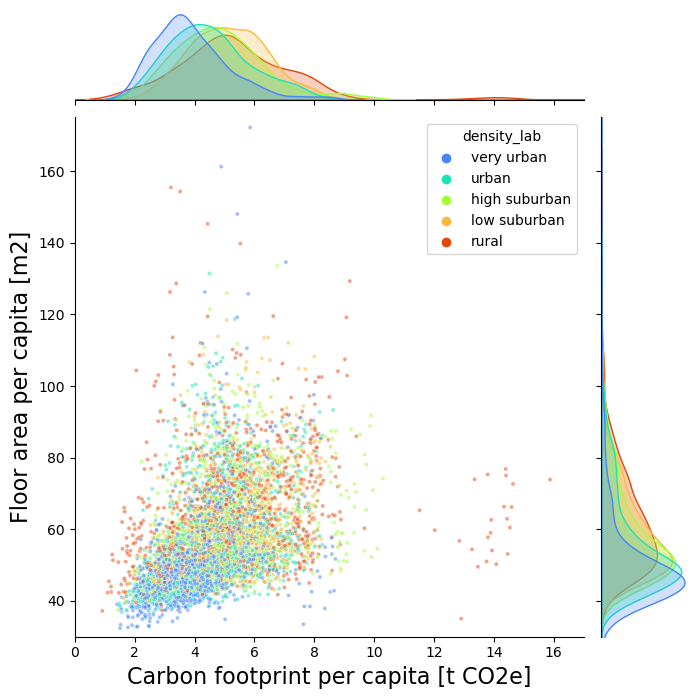

In [596]:
df = ghg_annual_sum_m2_cap.reset_index()
g = sns.jointplot(y="size"+year+"_w1", x="t_co2e", hue='density_lab', data=df,
                  #kind="kde", truncate=False,
                  marker='.',
                  joint_kws={"alpha": 0.5},
                  palette='turbo',
                  #line_kws={"color": "darkred","alpha": 0.4},
                  xlim=(0, 17), ylim=(30, 175),
                  color="0.3", 
                  height=7,
                  )
g.set_axis_labels('Carbon footprint per capita [t CO2e]', 'Floor area per capita [m2]', fontsize=16)
g.savefig('visualisations/scatter_ghg_m2_urb'+year+'.png')

In [597]:
    ghg_annual_size = ghg_annual.copy()
    ghg_annual_size['size_lab'] = 'medium'
    use_m2_per_cap = use['size'+year+'_w1']*use['n_hhd']/use['n_hhdmem'+year]
    ghg_annual_size.loc[use_m2_per_cap<use_m2_per_cap.quantile(0.25), 'size_lab'] = 'smallest'
    ghg_annual_size.loc[use_m2_per_cap>use_m2_per_cap.quantile(0.75), 'size_lab'] = 'largest'
    ghg_annual_size = ghg_annual_size.assign(size_lab=ghg_annual_size['size_lab']).set_index('size_lab', append=True)
    ghg_annual_size.columns = ['Building material', 'Heat pump', 'District heating', 'Gas', 'Electricity', 'PV', 'Car use', 'Transit', 'Cycling']
    #ghg_annual_size.columns = ['Construction', 'Heating', 'Heating', 'Heating', 'Electricity', 'Electricity', 'Mobility', 'Mobility', 'Mobility']

    df = (ghg_annual_size.multiply(use['n_hhd'], axis=0).div(use['n_hhdmem'+year], axis=0)/1000).groupby(level=5, sort=False).mean().unstack().reset_index()
    df.columns = ['process', 'floor area', 'value']

    fig = px.bar(df, x='value', y='floor area',color='process', 
                 #text=df['percentage'].apply(lambda x: '{0:.1%}'.format(x)), 
                 labels={'value':'Carbon footprint of housing per capita per year [t CO<sub>2</sub>e]'}, 
                 template='simple_white', 
             color_discrete_sequence=['rgb(000,000,000)', #buildings                                       
                                        'rgb(204,121,167)', #hp
                                        'rgb(126,041,084)', #dh,
                                        'rgb(213,094,000)', #gas
                                        'rgb(230,159,000)', #elec
                                        'rgb(240,228,066)', #pv                                  
                                        'rgb(000,114,178)', #car
                                        'rgb(086,180,233)', #transit                                         
                                        'rgb(000,158,115)', #cycling
                                        ]) 
    #fig.update_traces(textposition='inside')
    fig.update_layout(width=1000, height=300, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=18),
                      legend=dict(
        orientation="h",
        #entrywidth=70,
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25
    ))
    fig.update_traces(marker_line_width=0)
    fig.write_image('visualisations/stackedbars_ghg_per_cap_process_m2'+year+'.png', scale=3)
    fig.show()

In [598]:
    ghg_annual_size = ghg_annual.copy()
    ghg_annual_size['size_lab'] = 'medium'
    use_m2_per_cap = use['size'+year+'_w1']*use['n_hhd']/use['n_hhdmem'+year]
    ghg_annual_size.loc[use_m2_per_cap<use_m2_per_cap.quantile(0.25), 'size_lab'] = 'smallest'
    ghg_annual_size.loc[use_m2_per_cap>use_m2_per_cap.quantile(0.75), 'size_lab'] = 'largest'
    ghg_annual_size = ghg_annual_size.assign(size_lab=ghg_annual_size['size_lab']).set_index('size_lab', append=True)
    #ghg_annual_size.columns = ['Building material', 'Heat pump', 'District heating', 'Gas', 'Electricity', 'PV', 'Car use', 'Transit', 'Cycling']
    ghg_annual_size.columns = ['Construction', 'Heating', 'Heating', 'Heating', 'Electricity', 'Electricity', 'Mobility', 'Mobility', 'Mobility']
    ghg_annual_size = ghg_annual_size.groupby(level=0, axis=1, sort=False).sum()

    df = (ghg_annual_size.multiply(use['n_hhd'], axis=0).div(use['n_hhdmem'+year], axis=0)/1000).groupby(level=5, sort=False).mean().unstack().reset_index()
    df.columns = ['process', 'floor area', 'value']

    fig = px.bar(df, x='value', y='floor area',color='process', 
                 #text=df['percentage'].apply(lambda x: '{0:.1%}'.format(x)), 
                 labels={'value':'Carbon footprint of housing per capita per year [t CO<sub>2</sub>e]'}, 
                 template='simple_white', 
             color_discrete_sequence=['rgb(000,000,000)', #buildings                                       
                                        'rgb(213,094,000)', #gas
                                        'rgb(230,159,000)', #elec                               
                                        'rgb(000,114,178)', #car
                                        ]) 
    #fig.update_traces(textposition='inside')
    fig.update_layout(width=1000, height=300, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=18),
                      legend=dict(
        orientation="h",
        #entrywidth=70,
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25
    ))
    fig.update_traces(marker_line_width=0)
    fig.write_image('visualisations/stackedbars_ghg_per_cap_agg_m2'+year+'.png', scale=3)
    fig.show()

In [599]:
    ghg_annual_size = ghg_annual.copy()
    ghg_annual_size['size_lab'] = 'medium'
    use_m2_per_cap = use['size'+year+'_w1']*use['n_hhd']/use['n_hhdmem'+year]
    ghg_annual_size.loc[use_m2_per_cap<use_m2_per_cap.quantile(0.25), 'size_lab'] = 'smallest'
    ghg_annual_size.loc[use_m2_per_cap>use_m2_per_cap.quantile(0.75), 'size_lab'] = 'largest'
    ghg_annual_size = ghg_annual_size.assign(size_lab=ghg_annual_size['size_lab']).set_index('size_lab', append=True)
    #ghg_annual_size.columns = ['Building material', 'Heat pump', 'District heating', 'Gas', 'Electricity', 'PV', 'Car use', 'Transit', 'Cycling']
    ghg_annual_size.columns = ['Housing', 'Housing', 'Housing', 'Housing', 'Housing', 'Housing', 'Housing', 'Housing', 'Housing']
    ghg_annual_size = ghg_annual_size.groupby(level=0, axis=1, sort=False).sum()

    df = (ghg_annual_size.multiply(use['n_hhd'], axis=0).div(use['n_hhdmem'+year], axis=0)/1000).groupby(level=5, sort=False).mean().unstack().reset_index()
    df.columns = ['process', 'floor area', 'value']

    fig = px.bar(df, x='value', y='floor area',color='process', 
                 #text=df['percentage'].apply(lambda x: '{0:.1%}'.format(x)), 
                 labels={'value':'Carbon footprint of housing per capita per year [t CO<sub>2</sub>e]'}, 
                 template='simple_white', 
             color_discrete_sequence=['rgb(000,000,000)', #buildings                                       
                                        'rgb(213,094,000)', #gas
                                        'rgb(230,159,000)', #elec                               
                                        'rgb(000,114,178)', #car
                                        ]) 
    #fig.update_traces(textposition='inside')
    fig.update_layout(width=1000, height=300, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=18),
                      legend=dict(
        orientation="h",
        #entrywidth=70,
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25
    ))
    fig.update_traces(marker_line_width=0)
    fig.write_image('visualisations/stackedbars_ghg_per_cap_total_m2'+year+'.png', scale=3)
    fig.show()

In [600]:
    ghg_annual_df = ghg_annual.copy()
    ghg_annual_df = ghg_annual_df/1000 #conversion to t co2e
    ghg_annual_df.columns = ['Building material', 'Heat pump', 'District heating', 'Gas', 'Electricity', 'PV', 'Car use', 'Transit', 'Cycling']
    #ghg_annual_df.columns = ['Construction', 'Heating', 'Heating', 'Heating', 'Electricity', 'Electricity', 'Mobility', 'Mobility', 'Mobility']
    #ghg_annual_df = ghg_annual_df.groupby(level=0, axis=1, sort=False).sum()
    df = ghg_annual_df.multiply(use['n_hhd'], axis=0).div(use['n_hhdmem'+year], axis=0).groupby(level=0, sort=False).mean().unstack().reset_index()
    df.columns = ['process', 'income level', 'value']

    fig = px.bar(df, x='value', y='income level',color='process', 
                 #text=df['percentage'].apply(lambda x: '{0:.1%}'.format(x)), 
                 labels={'value':'Carbon footprint of housing per capita per year [t CO<sub>2</sub>e]'}, 
                 template='simple_white', 
             color_discrete_sequence=['rgb(000,000,000)', #buildings                                       
                                        'rgb(204,121,167)', #hp
                                        'rgb(126,041,084)', #dh,
                                        'rgb(213,094,000)', #gas
                                        'rgb(230,159,000)', #elec
                                        'rgb(240,228,066)', #pv                                  
                                        'rgb(000,114,178)', #car
                                        'rgb(086,180,233)', #transit                                         
                                        'rgb(000,158,115)', #cycling
                                        ]) 
    #fig.update_traces(textposition='inside')
    fig.update_layout(width=1000, height=500, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=18),
                      legend=dict(
        orientation="h",
        #entrywidth=70,
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25
    ))
    fig.update_traces(marker_line_width=0)
fig.write_image('visualisations/stackedbars_ghg_per_cap_process_inc'+year+'.png', scale=3)
fig.show()

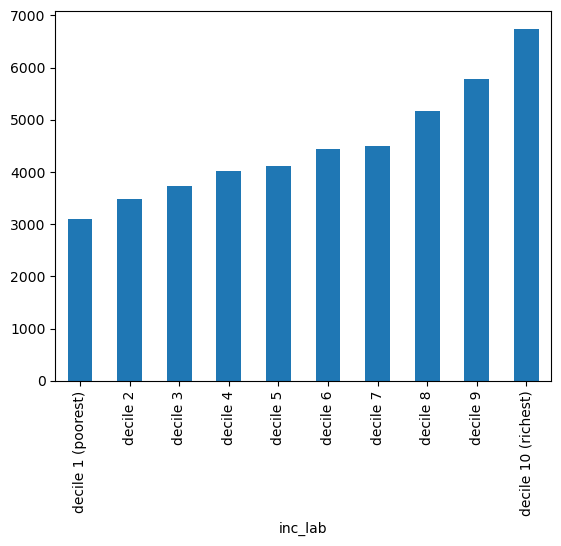

In [601]:
#floor area per income level
use_m2_total_inc = (ghg_annual.sum(1)*use['n_hhd']).groupby(level=0, sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc = use['n_hhdmem'+year].groupby(level=0, sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group
use_m2_per_cap_inc.plot(kind='bar') #per person
"""interpretation: especially the highest income decile has considerably more floor area available than the vast majority"""

#floor area per income level and building type
use_m2_total_inc_type = (ghg_annual.sum(1)*use['n_hhd']).groupby(level=[0,1], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc_type = use['n_hhdmem'+year].groupby(level=[0,1], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc_type = use_m2_total_inc_type / use_cap_total_inc_type #m2/cap in each income group

#preparing the dataframes for plotting
df = use_m2_per_cap_inc
df2=use_m2_per_cap_inc_type.rename('value').to_frame()
df2['n_hhd'] = use['n_hhd'].groupby(level=[0,1], sort=False).sum()
df2 = df2.reset_index()

#plot
colors = ['#000000', #construction
                            '#fe6100', #buildings                                              
                                        '#648fff', #roads
                                        '#785ef0', #railways
                                        '#ffb000', #electricity
                                        '#808080', #other civil engineering
                                        '#000000', #construction
                                        ]
fig = px.bar(df, x=df.values, y=df.index,  
             labels={'x':'kg CO2eq. per capita', 'inc_lab':'household income level'}, 
             template='simple_white', 
             color_discrete_sequence=colors) 
fig.update_layout(width=1000, height=500, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=18),
                      bargap=0.9,
                      legend=dict(
        orientation="h",
        #entrywidth=70,
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25,
    ))

df2=use_m2_per_cap_inc_type.rename('value').to_frame()
df2['n_hhd'] = use['n_hhd'].groupby(level=[0,1], sort=False).sum()

for i in df2.index.levels[1].to_list():
    df_plot = df2.xs(i, level=1)
    fig.add_trace(go.Scatter(
            y=df_plot.index, 
            x=df_plot['value'],
            mode='markers',
            name=i,
            marker=dict(size=df_plot['n_hhd'],
                        sizemode='area',
                        sizeref=4*max(df2['n_hhd'])/(40.**2),
                        sizemin=4,
                        #color=10*[0, 1, 2, 3],
                        ),
            showlegend=True
        ))
fig.update_traces(marker_line_width=0)
fig.write_image('visualisations/bubblechart_ghg_per_cap_inc_type'+year+'.png', scale=3)
fig.show()

In [602]:
#df = use[['inc_decile','size'+year+'_w1', 'gas'+year, 'n_heatpump'+year,'netelectricity'+year, 'car_pkm']].reset_index()
#sns.pairplot(df, hue="typology_lab", kind="reg", plot_kws={'scatter_kws': {'alpha': 0.1}})

# CODE ARCHIVE

In [603]:
# Configurations
mi_buildings_source = "Oorschot"  # Oorschot or Yang
# Load data
if mi_buildings_source == "Oorschot":
    mi_buildings = pd.read_excel(
        "data_input/MI_Buildings_Oorschot2023.xlsx",
        sheet_name="MI_2018",
        index_col=[0, 1],
        header=[0, 1],
    ).droplevel(1, axis=1)
    mi_buildings.index.names = ["Building type", "Cohort"]
    mi_buildings.columns.name = "Material"

    mi_buildings_2018 = pd.read_excel(
        "data_input/MI_Buildings_Oorschot2023.xlsx",
        sheet_name="MI_2018-2050",
        index_col=[0],
        header=[0, 1],
        skipfooter=20,
    ).droplevel(1, axis=1)
    mi_buildings_2018["Cohort"] = "2018"
    mi_buildings_2018.reset_index(inplace=True)
    mi_buildings_2018["index"] = [i.lower() for i in mi_buildings_2018["index"]]
    mi_buildings_2018.set_index(["index", "Cohort"], inplace=True)
    mi_buildings_2018.index.names = ["Building type", "Cohort"]
    mi_buildings_2018.columns.name = "Material"

    mi_buildings_insulation_share = pd.read_excel(
        "data_input/MI_Buildings_Oorschot2023.xlsx",
        sheet_name="Share_of_insulation_materials",
        index_col=[0, 1],
        header=[0],
        skipfooter=3,
    ).drop("Unnamed: 8", axis=1)
    for i in mi_buildings_insulation_share.columns:
        mi_buildings[i] = (
            mi_buildings["Insulation"] * mi_buildings_insulation_share[i].iloc[0]
        )
        mi_buildings_2018[i] = (
            mi_buildings_2018["Insulation"] * mi_buildings_insulation_share[i].iloc[1]
        )

    mi_buildings = (
        pd.concat([mi_buildings, mi_buildings_2018], axis=1)
        .T.groupby(level=0)
        .sum()
        .T.sort_index()
        .replace(0, np.nan)
        .dropna(how="all", axis=1)
        .drop("Insulation", axis=1)
    )

# matching material names
replacement_map = {'Bitumen':'Bitumen', #soon
                    'Brick':'Ceramics', #BRIK,
                    'Clay brick':'Ceramics', #BRIK
                    'Ceramics':'Ceramics', #BRIK (bricks, tiles, construction products)
                    'Sand-lime brick':'Ceramics', #BRIK
                    'Sand':'Sand', #SDCL
                    'Concrete':'Concrete', #CMNT (only lime,cement and plast, no mix)
                    'Mortal':'Mortar', #CMNT
                    'Gypsum':'Mortar', #CMNT (plaster of gypsum)
                    'Aluminum':'Aluminium', #ALUM
                    'Copper':'Copper', #COPP
                    'Other metals':'Other metals', #ONFM
                    'Electronics':'Electronics', #ELMA
                    'Glass':'Glass', #GLAS 
                    'Glass wool':'Glass', #GLAS (includes explicitely glass wool)
                    'Stone wool':'Mineral wool', #ONMM (includes explicitely mineral wool)
                    'Iron & steel':'Steel', #STEL or FABM
                    'Steel':'Steel', #STEL or FABM
                    'Other biobased materials':'Wood and straw', #WOOD
                    'Wood':'Wood and straw', #WOOD
                    'Other construction materials':'Other construction material', #ONMM, could also be STON, SDCL or CMNT
                    'Other':'Adhesives and paint', #could be CHEM, PLAS, PAPE, ELMA
                    'Paper':'Paper', #PAPE 
                    'Expanded polystyrene':'Plastic', #RUBP 
                    'Extruded polystyrene':'Plastic', #RUBP
                    'Plastic':'Plastic', #RUBP
                    'Plastics':'Plastic', #RUBP
                    'Polyurethanes':'Plastic', #RUBP
                    'Adhesives & paint':'Adhesives and paint', #CHEM (other chemical products, for glues) or PLAS (basic plastics) 
                    'Stone':'Stone', #STON
                    }

mi_buildings = mi_buildings.stack().reset_index()
mi_buildings['Material_group'] = mi_buildings['Material'].map(replacement_map)
mi_buildings.replace('<1945','1944', inplace=True)
mi_buildings = mi_buildings.drop('Material', axis=1).groupby(['Building type', 'Cohort', 'Material_group']).sum().unstack().droplevel(0, axis=1)

#selecting only residential buildings
mi_buildings.drop(['industry', 'office', 'services', 'shop'], axis=0, level=0, inplace=True)

TypeError: can't multiply sequence by non-int of type 'float'

In [ ]:
# Configurations
ei_heating_source = "TABULA"  # Oorschot or Yang
# Load data
if ei_heating_source == "TABULA":
    ei_heating = pd.read_excel(
        "data_input/EI_Heating_HotWater_TABULA2017.xlsx",
        sheet_name="0_EnergyDemandIntensity",
        index_col=[0],
        header=[0],
    ).drop('Default Heating & Hot Water', axis=1)

In [ ]:
m_plot = ei_heating.copy()

m_plot = m_plot.stack().reset_index()
m_plot.columns = ['building', 'function', 'value']
fig = px.bar(m_plot, x='value', y='building', color='function', labels={'value':'energy intensity per floor area [kWh/m2]'}, template='simple_white', 
             color_discrete_sequence= px.colors.qualitative.Prism) #antique, vivid, prism, T10
fig.update_layout(width=500, height=1200, yaxis = dict(autorange="reversed"))    
fig.write_image('visualisations/ei_heating'+ei_heating_source+'.svg')
fig.show()

In [ ]:
# Configurations
mi_buildings_source = "Yang"  # Oorschot or Yang
# Load data
if mi_buildings_source == "Yang":
    mi_buildings = pd.read_excel(
        "data_input/MI_Buildings_Yang2022.xlsx",
        sheet_name='0_MaterialIntensity',
        index_col=[0, 1],
        header=[0, 1],
    ).droplevel(0, axis=0).droplevel(1, axis=1)
    mi_buildings.index.names = ["Building type"]
    mi_buildings.columns.name = "Material"

    # matching material names
    replacement_map = {'bitumen adhesive compound, hot':'Bitumen', #soon
                        'clay brick':'Ceramics', #BRIK
                        'ceramic tile':'Ceramics', #BRIK (bricks, tiles, construction products)
                        'sand':'Sand', #SDCL
                        'concrete, normal':'Concrete', #CMNT (only lime,cement and plast, no mix)
                        'fibre-reinforced concrete':'Concrete', #CMNT (only lime,cement and plast, no mix)
                        'cement mortar':'Mortar', #CMNT
                        'gypsum, mineral':'Mortar', #CMNT (plaster of gypsum)
                        'aluminium, wrought alloy':'Aluminium', #ALUM ##
                        'copper':'Copper', #COPP
                        'zinc':'Zinc', #LZNC
                        'flat glass, coated':'Glass', #GLAS 
                        'glass wool mat':'Glass', #GLAS (includes explicitely glass wool)
                        'cast iron':'Steel', #STEL or FABM
                        'wire drawing, steel':'Steel', #STEL or FABM
                        'plywood, for indoor use':'Wood and straw', #WOOD
                        'sawnwood, hardwood, raw':'Wood and straw', #WOOD
                        'sawnwood, softwood, raw':'Wood and straw', #WOOD
                        'fibreboard, soft':'Wood and straw', #WOOD
                        'polystyrene, expandable':'Plastic', #RUBP 
                        'polystyrene, extruded':'Plastic', #RUBP
                        'extrusion, plastic pipes':'Plastic', #RUBP
                        'polyurethane, flexible foam':'Plastic', #RUBP
                        'gravel, crushed':'Stone', #STON
                        'argon, liquid':'Argon', #CHEM
                        }

    mi_buildings = mi_buildings.stack().reset_index()
    mi_buildings['Material_group'] = mi_buildings['Material'].map(replacement_map)
    mi_buildings = mi_buildings.drop('Material', axis=1).groupby(['Building type', 'Material_group']).sum().unstack().droplevel(0, axis=1)

    nzeb = mi_buildings.loc[(mi_buildings.index.str.contains('_NZEB')) & ~(mi_buildings.index.str.contains('new'))]
    nzeb.index = [i[:-5] for i in nzeb.index]
    nzeb = nzeb + mi_buildings.loc[~(mi_buildings.index.str.contains('_NZEB')) & ~(mi_buildings.index.str.contains('new'))]
    nzeb.index = [i+'_NZEB' for i in nzeb.index]
    mi_buildings.update(nzeb)

In [ ]:
m_plot = mi_buildings[~mi_buildings.duplicated()]
m_plot = m_plot.stack().reset_index()
m_plot.columns = ['building', 'material', 'value']
fig = px.bar(m_plot, x='value', y='building', color='material', labels={'value':'material intensity per floor area [kg/m2]', 'sector':'Input sector'}, template='simple_white', 
             color_discrete_sequence= px.colors.qualitative.Prism) #antique, vivid, prism, T10
fig.update_layout(width=1100, height=700, yaxis = dict(autorange="reversed"))    
fig.write_image('visualisations/mi_buildings'+mi_buildings_source+'.svg')
fig.show()